<a href="https://colab.research.google.com/github/Epidemic2001/PetProyects_Studies/blob/main/03_Stacking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Ensemble Learning con Breast Cancer Wisconsin

Este notebook utiliza el dataset real **Breast Cancer Wisconsin (Diagnostic)** incluido en `scikit-learn`.

- 569 observaciones.
- 30 variables numéricas.
- Variable objetivo binaria:
  - `0 = malignant`
  - `1 = benign`

El dataset se carga directamente desde `scikit-learn`, por lo que **no es necesario descargar un CSV externo**.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Cargar dataset real
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

df = data.frame.copy()

print("Dimensiones:", df.shape)
print("\nClases:", list(data.target_names))
print("\nDistribución de clases:")
print(y.value_counts().sort_index())

df.head()

Dimensiones: (569, 31)

Clases: [np.str_('malignant'), np.str_('benign')]

Distribución de clases:
target
0    212
1    357
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Exportación opcional del dataset

In [ ]:
# OPCIONAL: exportar el dataset a CSV
df.to_csv("breast_cancer_wisconsin.csv", index=False)

print("Archivo creado: breast_cancer_wisconsin.csv")

Archivo creado: breast_cancer_wisconsin.csv


## División train/test

In [ ]:
# Separación entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (426, 30)
Test : (143, 30)


## 1. Modelos base

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

estimators = [
    (
        "logistic",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        )
    ),
    (
        "knn",
        make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=7)
        )
    ),
    (
        "svm",
        make_pipeline(
            StandardScaler(),
            SVC(probability=True, kernel="rbf")
        )
    )
]

## 2. Rendimiento individual de los modelos base

In [ ]:
base_results = []

for name, model in estimators:
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]

    base_results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

pd.DataFrame(base_results)

,Modelo,Accuracy,F1,ROC-AUC
0,logistic,0.986014,0.988889,0.997694
1,knn,0.979021,0.983607,0.992348
2,svm,0.979021,0.983240,0.996855


## 3. Stacking

Las predicciones de los modelos base se transforman en nuevas variables para un modelo final o **meta-modelo**.

In [ ]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=5000),
    cv=5,
    n_jobs=-1
)

stacking.fit(X_train, y_train)

pred_stacking = stacking.predict(X_test)

print(
    "Accuracy Stacking:",
    accuracy_score(y_test, pred_stacking)
)

Accuracy Stacking: 0.986013986013986


## 4. ¿Los modelos base se equivocan en los mismos casos?

In [ ]:
base_predictions = pd.DataFrame(index=X_test.index)

for name, model in estimators:
    model.fit(X_train, y_train)
    base_predictions[name] = model.predict(X_test)

base_predictions["real"] = y_test

base_predictions.head(15)

,logistic,knn,svm,real
519,1,1,1,1
408,0,0,0,0
291,1,1,1,1
518,1,1,1,1
385,0,0,0,0
535,0,0,0,0
8,0,0,0,0
127,0,0,0,0
372,0,0,0,0
398,1,1,1,1


In [ ]:
errors = pd.DataFrame(index=X_test.index)

for column in ["logistic", "knn", "svm"]:
    errors[column] = (
        base_predictions[column] != base_predictions["real"]
    ).astype(int)

error_correlation = errors.corr()
error_correlation

,logistic,knn,svm
logistic,1.000000,0.398081,0.813596
knn,0.398081,1.000000,0.319048
svm,0.813596,0.319048,1.000000


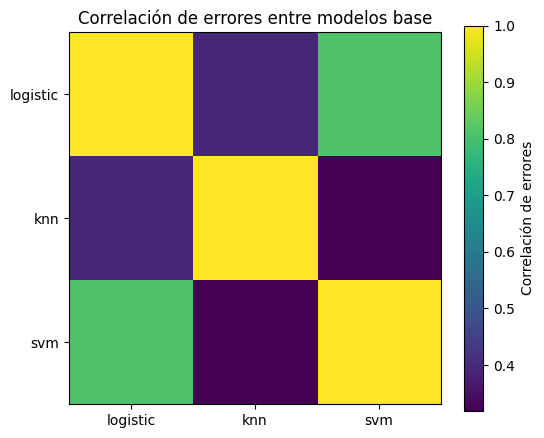

In [ ]:
plt.figure(figsize=(6,5))

plt.imshow(
    error_correlation,
    interpolation="nearest"
)

plt.xticks(
    range(len(error_correlation.columns)),
    error_correlation.columns
)

plt.yticks(
    range(len(error_correlation.columns)),
    error_correlation.columns
)

plt.colorbar(label="Correlación de errores")
plt.title("Correlación de errores entre modelos base")
plt.show()

## 5. Comparación de modelos base vs Stacking

In [ ]:
def evaluar_modelo(nombre, modelo, X_test, y_test):
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

In [ ]:
comparison = []

for name, model in estimators:
    comparison.append(
        evaluar_modelo(name, model, X_test, y_test)
    )

comparison.append(
    evaluar_modelo("Stacking", stacking, X_test, y_test)
)

results_df = pd.DataFrame(comparison)
results_df

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,logistic,0.986014,0.988889,0.988889,0.988889,0.997694
1,knn,0.979021,0.967742,1.000000,0.983607,0.992348
2,svm,0.979021,0.988764,0.977778,0.983240,0.996855
3,Stacking,0.986014,0.988889,0.988889,0.988889,0.997694


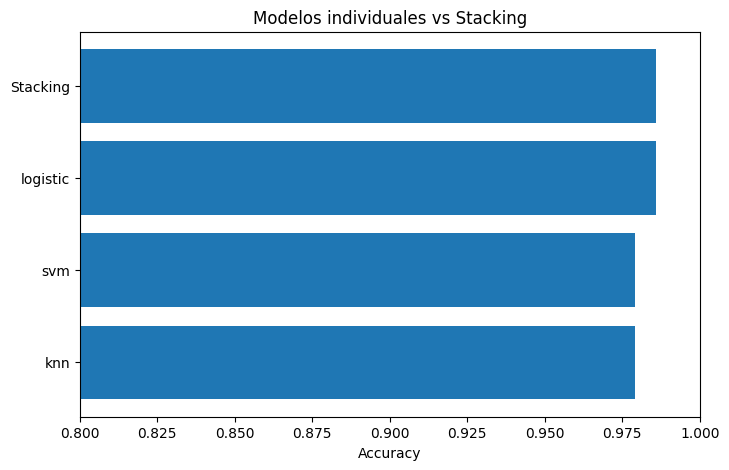

In [ ]:
ordered = results_df.sort_values("Accuracy")

plt.figure(figsize=(8,5))
plt.barh(
    ordered["Modelo"],
    ordered["Accuracy"]
)

plt.xlabel("Accuracy")
plt.title("Modelos individuales vs Stacking")
plt.xlim(0.8, 1.0)
plt.show()

## 6. Curvas ROC

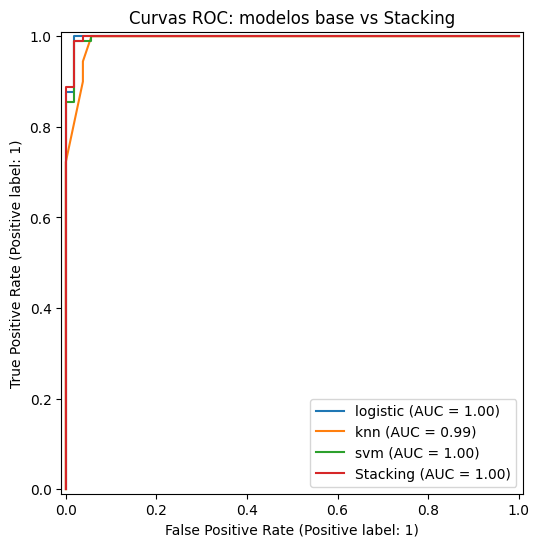

In [ ]:
plt.figure(figsize=(8,6))
ax = plt.gca()

for name, model in estimators:
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name
    )

RocCurveDisplay.from_estimator(
    stacking,
    X_test,
    y_test,
    ax=ax,
    name="Stacking"
)

plt.title("Curvas ROC: modelos base vs Stacking")
plt.show()

## Preguntas de análisis

- ¿El mejor modelo individual es necesariamente igual al mejor ensemble?
- ¿Por qué conviene que los modelos base sean diferentes?
- ¿Qué significa que dos modelos tengan errores muy correlacionados?
- ¿Qué función cumple el meta-modelo?
- ¿Qué ocurriría si todos los modelos base fueran casi idénticos?